# Puesta en producción: del modelo a la web con Vercel
**Curso Machine Learning · Josef Renato Rodriguez**

Hoy llevamos un modelo de riesgo de tarjetas de punta a punta:

1. Datos históricos con target `default_3m` (default en los próximos 3 meses)
2. Entrenamiento con split temporal (train 2024, test 2025-S1, OOT 2025-S2)
3. Bandas de riesgo por quintiles: **Muy alto, Alto, Medio, Bajo, Muy bajo**
4. Serialización del modelo (artefacto `.joblib`)
5. Scoring de la campaña del mes desde un `.txt`
6. API con FastAPI + página web, publicada en **Vercel**

## 1. Datos
Solo 6 variables, pensadas para que el formulario web sea fácil de llenar:

| Variable | Descripción | Efecto esperado en el riesgo |
|---|---|---|
| `edad` | Edad del cliente (años) | ↓ a mayor edad |
| `ingreso_mensual` | Ingreso mensual declarado (S/) | ↓ a mayor ingreso |
| `antiguedad_meses` | Meses como cliente del banco | ↓ a mayor antigüedad |
| `utilizacion_linea` | % de la línea de crédito usada (puede pasar 100) | ↑ |
| `max_dias_atraso_6m` | Máximo atraso en los últimos 6 meses (días) | ↑ |
| `consultas_3m` | Consultas en centrales de riesgo en 3 meses | ↑ |

In [1]:
from pathlib import Path
import joblib, numpy as np, pandas as pd, sklearn
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

# Busca la carpeta del proyecto (la que tiene data/riesgo_tarjetas_hist.csv) desde donde abras el notebook:
# Clase_14/APP, APP/notebooks, Clase_14/Notebooks o la raíz del repo. Si no la encuentra (Colab), usa la carpeta actual.
_aqui = Path.cwd()
_candidatas = [_aqui, _aqui.parent, _aqui / "APP", _aqui.parent / "APP", _aqui / "Clase_14" / "APP"]
BASE = next((p for p in _candidatas if (p / "data" / "riesgo_tarjetas_hist.csv").exists()), _aqui)
(BASE / "data").mkdir(exist_ok=True); (BASE / "model").mkdir(exist_ok=True)
URL_GITHUB = "https://raw.githubusercontent.com/josefrodrim/Super_ML_course/main/Clase_14/APP/data/"

def leer(nombre, **kw):
    """Lee de data/ local si existe; si no (Colab), lo baja de GitHub."""
    local = BASE / "data" / nombre
    return pd.read_csv(local if local.exists() else URL_GITHUB + nombre, **kw)

df = leer("riesgo_tarjetas_hist.csv", dtype={"periodo": str})
print(df.shape, "| sklearn", sklearn.__version__)
df.head()

(24000, 9) | sklearn 1.9.1


,id_cliente,periodo,edad,ingreso_mensual,antiguedad_meses,utilizacion_linea,max_dias_atraso_6m,consultas_3m,default_3m
0,C020101,202401,67,1490.0,50,40.7,5,1,0
1,C059577,202401,30,3880.0,33,19.6,0,5,0
2,C023485,202401,22,4230.0,5,68.3,0,3,0
3,C001802,202401,56,5870.0,25,72.5,5,2,0
4,C022773,202401,41,1760.0,39,51.2,10,2,0


In [2]:
FEATURES = ["edad", "ingreso_mensual", "antiguedad_meses",
            "utilizacion_linea", "max_dias_atraso_6m", "consultas_3m"]
TARGET = "default_3m"
df[FEATURES + [TARGET]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
edad,24000.0,48.11,15.87,21.0,34.00,48.0,62.0,75.0
ingreso_mensual,24000.0,4198.59,2723.41,1130.0,2340.00,3520.0,5232.5,30000.0
antiguedad_meses,24000.0,58.92,53.71,1.0,19.00,42.0,83.0,240.0
utilizacion_linea,24000.0,43.22,21.45,0.0,27.08,41.9,58.3,120.0
max_dias_atraso_6m,24000.0,3.50,12.94,0.0,0.00,0.0,0.0,120.0
consultas_3m,24000.0,2.06,1.48,0.0,1.00,2.0,3.0,10.0
default_3m,24000.0,0.06,0.24,0.0,0.00,0.0,0.0,1.0


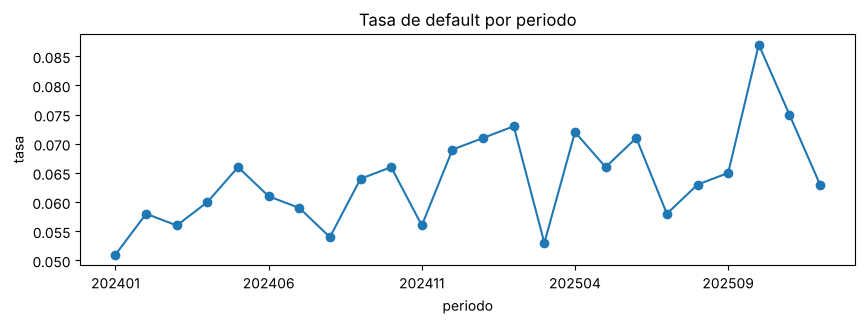

In [3]:
tasa = df.groupby("periodo")[TARGET].mean()
ax = tasa.plot(figsize=(10, 3), marker="o", title="Tasa de default por periodo")
ax.set_ylabel("tasa"); plt.show()

## 2. Split temporal
En producción el modelo siempre puntúa **meses futuros**, así que validamos igual:
- **Train**: 2024
- **Test**: 2025-01 a 2025-06
- **OOT**: 2025-07 a 2025-12

In [4]:
train = df[df.periodo < "202501"]
test  = df[(df.periodo >= "202501") & (df.periodo < "202507")]
oot   = df[df.periodo >= "202507"]
for n, d in [("train", train), ("test", test), ("oot", oot)]:
    print(f"{n:>5}: {len(d):>6} filas | default {d[TARGET].mean():.2%}")

train:  12000 filas | default 6.00%
 test:   6000 filas | default 6.77%
  oot:   6000 filas | default 6.85%


## 3. Modelos
Comparamos una regresión logística (baseline) con `HistGradientBoostingClassifier`,
el boosting por histogramas de scikit-learn (la misma idea de LightGBM).

Le ponemos **restricciones monótonas**: si sube la utilización de la línea, el riesgo
nunca puede bajar. En riesgo de crédito esto es clave para que el modelo sea explicable
y defendible ante validación y el regulador.

> ¿Por qué no LightGBM/XGBoost aquí? Rinden parecido, pero para desplegar en Vercel
> queremos el paquete más liviano y sin dependencias del sistema (LightGBM en Mac pide `libomp`).

In [5]:
def ks(y, p):
    d = pd.DataFrame({"y": y, "p": p}).sort_values("p")
    return ((d.y == 1).cumsum() / (d.y == 1).sum() - (d.y == 0).cumsum() / (d.y == 0).sum()).abs().max()

modelos = {
    "Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "HGB monótono": HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=80,
        l2_regularization=1.0, monotonic_cst=[-1, -1, -1, 1, 1, 1], random_state=42),
}
filas = []
for nombre, m in modelos.items():
    m.fit(train[FEATURES], train[TARGET])
    for parte, d in [("train", train), ("test", test), ("oot", oot)]:
        p = m.predict_proba(d[FEATURES])[:, 1]
        auc = roc_auc_score(d[TARGET], p)
        filas.append({"modelo": nombre, "muestra": parte, "AUC": auc, "Gini": 2*auc-1, "KS": ks(d[TARGET].values, p)})
pd.DataFrame(filas).pivot(index="modelo", columns="muestra", values=["Gini", "KS"]).round(3)

Gini                   KS              
muestra         oot   test  train    oot   test  train
modelo                                                
HGB monótono  0.546  0.533  0.583  0.423  0.388  0.427
Logística     0.540  0.540  0.527  0.408  0.387  0.386

## 4. Bandas de riesgo para campañas
Los cortes se calculan **una sola vez** con los quintiles del score en train y se **congelan**.
Si recalculáramos quintiles con cada archivo nuevo, siempre saldría 20% por banda
y no veríamos cuando la cartera se deteriora (drift).

In [6]:
modelo = modelos["HGB monótono"]
BANDAS = ["Muy bajo", "Bajo", "Medio", "Alto", "Muy alto"]
p_train = modelo.predict_proba(train[FEATURES])[:, 1]
CORTES = np.quantile(p_train, [0.2, 0.4, 0.6, 0.8]).tolist()
print("Cortes:", [round(c, 4) for c in CORTES])

def asignar_banda(prob):
    return pd.Categorical(np.array(BANDAS)[np.searchsorted(CORTES, prob, side="right")],
                          categories=BANDAS[::-1], ordered=True)

Cortes: [0.0159, 0.0273, 0.0451, 0.0803]


In [7]:
def tabla_bandas(d):
    t = d.assign(prob=modelo.predict_proba(d[FEATURES])[:, 1])
    t["banda"] = asignar_banda(t.prob.values)
    r = t.groupby("banda", observed=False).agg(clientes=(TARGET, "size"), defaults=(TARGET, "sum"),
                                               tasa_default=(TARGET, "mean"), prob_media=("prob", "mean"))
    r["pct_clientes"] = r.clientes / r.clientes.sum()
    r["lift"] = r.tasa_default / t[TARGET].mean()
    r["pct_defaults_capturados"] = (r.defaults / r.defaults.sum()).cumsum()
    return r.round(3)

print("TEST"); display(tabla_bandas(test))
print("OOT");  display(tabla_bandas(oot))

TEST


,clientes,defaults,tasa_default,prob_media,pct_clientes,lift,pct_defaults_capturados
banda,,,,,,,
Muy alto,1330,236,0.177,0.178,0.222,2.622,0.581
Alto,1293,76,0.059,0.061,0.216,0.869,0.768
Medio,1217,51,0.042,0.036,0.203,0.619,0.894
Bajo,1137,30,0.026,0.022,0.190,0.390,0.968
Muy bajo,1023,13,0.013,0.010,0.170,0.188,1.000


OOT


,clientes,defaults,tasa_default,prob_media,pct_clientes,lift,pct_defaults_capturados
banda,,,,,,,
Muy alto,1495,253,0.169,0.176,0.249,2.471,0.616
Alto,1319,87,0.066,0.061,0.220,0.963,0.827
Medio,1203,40,0.033,0.036,0.200,0.485,0.925
Bajo,1094,24,0.022,0.021,0.182,0.320,0.983
Muy bajo,889,7,0.008,0.010,0.148,0.115,1.000


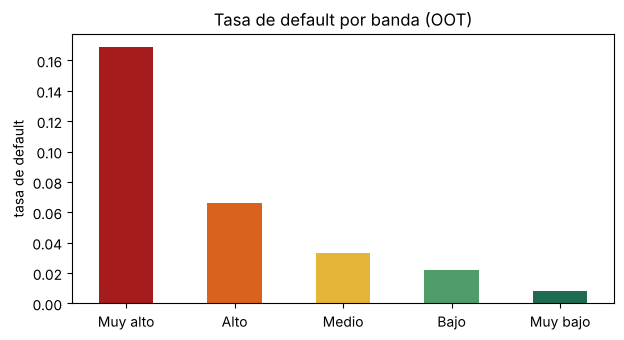

In [8]:
r = tabla_bandas(oot)
colores = ["#A61B1B", "#D9621E", "#E5B53A", "#4F9D69", "#1E6B52"]
ax = r.tasa_default.plot(kind="bar", color=colores, figsize=(7, 3.5), title="Tasa de default por banda (OOT)")
ax.set_ylabel("tasa de default"); ax.set_xlabel(""); plt.xticks(rotation=0); plt.show()

**Lectura:** las bandas deben **ordenar** el riesgo: la tasa de default cae de Muy alto a Muy bajo
sin saltos. Con esto la campaña decide, por ejemplo, ofrecer incremento de línea solo a Bajo y Muy bajo,
y revisar o excluir Muy alto.

## 5. Serializar el modelo (el artefacto)
En producción no viaja solo el modelo: viaja **todo lo necesario para puntuar igual que en desarrollo**.

In [9]:
artefacto = {
    "modelo": modelo,
    "features": FEATURES,          # orden exacto de columnas
    "cortes": CORTES,              # cortes congelados
    "bandas": BANDAS,
    "metricas": {n: {"auc": round(roc_auc_score(d[TARGET], modelo.predict_proba(d[FEATURES])[:, 1]), 4)}
                 for n, d in [("train", train), ("test", test), ("oot", oot)]},
    "version": pd.Timestamp.now().strftime("%Y%m%d-%H%M"),
    "sklearn_version": sklearn.__version__,   # ¡debe coincidir con requirements.txt!
}
ruta = BASE / "model" / "modelo_riesgo.joblib"
ruta.parent.mkdir(exist_ok=True)
joblib.dump(artefacto, ruta, compress=3)
print(f"{ruta.name}: {ruta.stat().st_size/1024:.0f} KB")

modelo_riesgo.joblib: 86 KB


In [10]:
# Prueba de humo: recargar y verificar que puntúa idéntico
cargado = joblib.load(ruta)
p1 = modelo.predict_proba(oot[FEATURES])[:, 1]
p2 = cargado["modelo"].predict_proba(oot[FEATURES])[:, 1]
print("Idénticos:", np.allclose(p1, p2))

Idénticos: True


## 6. Scoring de la campaña del mes (batch)
El área de campañas nos envía un `.txt` separado por `|` con los clientes de noviembre 2026 (sin target).
Lo validamos, lo puntuamos y devolvemos la banda de cada cliente.

In [11]:
camp = leer("campana_202611.txt", sep="|", dtype={"periodo": str, "id_cliente": str})
print(camp.shape); camp.head()

(3000, 8)


,id_cliente,periodo,edad,ingreso_mensual,antiguedad_meses,utilizacion_linea,max_dias_atraso_6m,consultas_3m
0,C070645,202611,50,6360.0,50,92.4,0,5
1,C066563,202611,46,3100.0,27,87.1,5,2
2,C063700,202611,29,1670.0,18,50.3,0,2
3,C071629,202611,57,3290.0,73,8.9,5,2
4,C098584,202611,45,3640.0,59,67.0,0,4


In [12]:
# Validación: columnas y rangos
RANGOS = {"edad": (18, 100), "ingreso_mensual": (0, 500000), "antiguedad_meses": (0, 600),
          "utilizacion_linea": (0, 150), "max_dias_atraso_6m": (0, 360), "consultas_3m": (0, 50)}
faltan = [c for c in FEATURES if c not in camp.columns]
assert not faltan, f"Faltan columnas: {faltan}"
invalido = camp[FEATURES].isna().any(axis=1)
for c, (lo, hi) in RANGOS.items():
    invalido |= ~camp[c].between(lo, hi)
print("Filas rechazadas:", invalido.sum())

ok = camp[~invalido].copy()
ok["prob_default"] = cargado["modelo"].predict_proba(ok[FEATURES])[:, 1].round(4)
ok["banda"] = asignar_banda(ok.prob_default.values)
resumen = ok.groupby("banda", observed=False).agg(clientes=("id_cliente", "size"), prob_media=("prob_default", "mean"))
resumen["pct"] = resumen.clientes / resumen.clientes.sum()
resumen["pct_desarrollo"] = 0.20
resumen.round(3)

Filas rechazadas: 0


,clientes,prob_media,pct,pct_desarrollo
banda,,,,
Muy alto,1024,0.195,0.341,0.2
Alto,693,0.061,0.231,0.2
Medio,570,0.036,0.190,0.2
Bajo,430,0.021,0.143,0.2
Muy bajo,283,0.011,0.094,0.2


### PSI: ¿se parece la campaña a la población de desarrollo?
$$PSI = \sum (\%actual - \%esperado)\cdot \ln\frac{\%actual}{\%esperado}$$
Regla práctica: < 0.10 estable · 0.10–0.25 vigilar · > 0.25 cambio fuerte.

In [13]:
a = resumen.pct.clip(lower=1e-4).values
psi = np.sum((a - 0.2) * np.log(a / 0.2))
print(f"PSI campaña vs desarrollo: {psi:.3f}")

PSI campaña vs desarrollo: 0.179


In [14]:
salida = BASE / "data" / "campana_202611_scored.csv"
ok.sort_values(["banda", "prob_default"], ascending=[True, False]) \
  [["id_cliente"] + FEATURES + ["prob_default", "banda"]].to_csv(salida, index=False)
print("Exportado:", salida.name)

Exportado: campana_202611_scored.csv


## 7. Del notebook a producción
El notebook sirve para explorar; producción necesita código **reproducible**:

```
score-app/
├── train.py              ← lo de las secciones 1–5, como script
├── model/modelo_riesgo.joblib
├── app.py                ← API FastAPI: /api/score y /api/campana
├── templates/index.html  ← la página web
├── requirements.txt      ← solo runtime, versiones fijadas
└── .python-version       ← 3.12
```

Levantar la API en local (con el entorno activado):
```bash
python train.py
uvicorn app:app --reload
```
Abre http://127.0.0.1:8000 (la web) y http://127.0.0.1:8000/docs (Swagger).

In [15]:
# Con la API corriendo en otra terminal, prueba desde Python:
import json, urllib.request
cliente = {"edad": 35, "ingreso_mensual": 3500, "antiguedad_meses": 24,
           "utilizacion_linea": 40, "max_dias_atraso_6m": 0, "consultas_3m": 1}
try:
    req = urllib.request.Request("http://127.0.0.1:8000/api/score", data=json.dumps(cliente).encode(),
                                 headers={"Content-Type": "application/json"})
    print(json.loads(urllib.request.urlopen(req, timeout=3).read()))
except Exception as e:
    print("La API no está corriendo:", type(e).__name__)

La API no está corriendo: URLError


## 8. Publicar en Vercel
1. Crear un repositorio en GitHub y subir el proyecto:
   ```bash
   git init
   git add .
   git commit -m "score de riesgo v1"
   git branch -M main
   git remote add origin https://github.com/TU_USUARIO/score-app.git
   git push -u origin main
   ```
2. En vercel.com → **Add New… → Project** → importar el repo `score-app` → **Deploy**.
   Vercel detecta FastAPI solo (encuentra `app` en `app.py`).
3. Abrir la URL `https://score-app-xxxx.vercel.app`, probar un cliente y subir `campana_202611.txt`.
4. Cambiar algo (por ejemplo, el título en `index.html`), hacer `git push` y ver el redeploy automático.

## 9. ¿Qué le falta para producción real en un banco?
- **Monitoreo**: PSI mensual por variable y por score, tasa de default observada vs. esperada
- **Logs y trazabilidad**: quién puntuó qué archivo, con qué versión del modelo
- **Seguridad**: autenticación, datos personales fuera de servicios públicos
- **Registro de modelos y reentrenamiento**: versiones, aprobación, rollback

Todo esto es lo que resuelven plataformas como **Databricks + MLflow** → próxima clase.